
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/10_Lab_langevineP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movimiento browniano

Una partícula inmersa en un líquido experimenta fricción y
fluctuaciones producidas por las colisiones moleculares.
Para una partícula libre, la ecuación de Langevin es

$$
m\frac{d^2x}{dt^2}
=
-\gamma\frac{dx}{dt}+\xi(t),
$$

donde $m$ es la masa, $\gamma$ es el coeficiente de fricción
y $\xi(t)$ es la fuerza fluctuante.

## Propiedades del ruido térmico

La fuerza fluctuante tiene media cero:

$$
\langle\xi(t)\rangle=0.
$$

Esto significa que las fluctuaciones no tienen una dirección
preferida en promedio.

Para un líquido en equilibrio térmico, la correlación es

$$
\langle\xi(t)\xi(t')\rangle
=
2\gamma k_BT\,\delta(t-t').
$$

La delta de Dirac es una distribución matemática, definida
por su acción dentro de una integral:

$$
\int_{-\infty}^{\infty}
\delta(t-t')f(t')\,dt'=f(t).
$$

La correlación del ruido blanco se concentra en tiempos
coincidentes y se anula para tiempos distintos. El ruido
blanco se interpreta mediante sus integrales temporales.

## Formulación mediante un proceso de Wiener

Definimos la velocidad:

$$
v=\frac{dx}{dt}.
$$

El sistema se escribe formalmente como

$$
\begin{aligned}
\frac{dx}{dt}&=v,\\
m\frac{dv}{dt}&=-\gamma v+\xi(t).
\end{aligned}
$$

Mediante un proceso de Wiener, su formulación precisa es

$$
\begin{aligned}
dx_t&=v_t\,dt,\\
m\,dv_t&=-\gamma v_t\,dt
+\sqrt{2\gamma k_BT}\,dW_t.
\end{aligned}
$$

Los incrementos de Wiener en intervalos disjuntos son
independientes y satisfacen

$$
\Delta W_n
=
W_{t_{n+1}}-W_{t_n}
\sim\mathcal{N}(0,\Delta t).
$$

Para generarlos numéricamente usamos

$$
\Delta W_n=\sqrt{\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1),
$$

con un nuevo $Z_n$ independiente en cada paso.

## Régimen sobreamortiguado

En escalas temporales grandes frente a $m/\gamma$, podemos
despreciar la inercia:

$$
\gamma\frac{dx}{dt}=\xi(t).
$$

La ecuación estocástica se reduce a

$$
dx_t=\sqrt{2D}\,dW_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Para una posición inicial fija $x_0$, la solución es

$$
x_t=x_0+\sqrt{2D}\,W_t,
\qquad W_0=0.
$$

La media permanece en la posición inicial y la varianza
aumenta linealmente:

$$
\mathbb{E}[x_t]=x_0,
\qquad
\operatorname{Var}(x_t)=2Dt.
$$

Entre dos tiempos, la actualización exacta de este modelo es

$$
x_{n+1}
=
x_n+\sqrt{2D\,\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1).
$$

Esta expresión describe una partícula libre en el régimen
sobreamortiguado.

Al incorporar un resorte, añadimos una deriva restauradora:

$$
dx_t
=
-\frac{k}{\gamma}x_t\,dt
+
\sqrt{2D}\,dW_t.
$$

Su aproximación de Euler–Maruyama es

$$
x_{n+1}
=
x_n-\frac{k}{\gamma}x_n\Delta t
+\sqrt{2D\,\Delta t}\,Z_n.
$$

El resorte confina las posiciones y el ruido mantiene las
fluctuaciones. A tiempos largos, la distribución se aproxima
a una gaussiana con media cero y varianza $k_BT/k$.

# Movimiento Browniano

\begin{equation}
\frac{d^2x}{dt^2}=-\gamma \frac{dx}{dt} + \xi(t)
\end{equation}

$\eta(t)$ Fuerza aleatoria producida por las colisiones colisiones moleculares $\langle \eta(t)\rangle=0.$, en promedio las colisiones que se presentan dan cero.
Para un liquido en equilibrio térmico, la intensidad viene dada por:

$\langle\xi(t)\xi(t') \rangle = 2\gamma k_B T  \delta(t-t') $

Para $\delta(\Delta t) = 0$, si $t!=t'$,

Para $\delta(\Delta t) = \infty$, si $t = t'$,



\begin{equation}
\frac{dx}{dt}=v
\end{equation}


\begin{equation}
\frac{dv}{dt}=-\gamma  \frac{dx}{dt} + \xi(t)
\end{equation}

El sistema de ecuaciones, se transforma, en, empleando un proceo de Wigner:


\begin{equation}
\begin{aligned}
dx(t)&=v(t)\,dt,\\
m\,dv(t)&=-\gamma v(t)\,dt
+\sqrt{2\gamma k_BT}\,dW(t).
\end{aligned}
\end{equation}



Cuya solución es

\begin{equation}
x(t+\Delta t)
=
x(t)+\sqrt{2D\,\Delta t}\,Z,
\qquad Z\sim\mathcal N(0,1).
\end{equation}



 # Simulacion del movimiento browniano

 Realizar un codigo para simular el movimiento browniano sin fuerza externa y con fuerza externa de la forma f=-kx

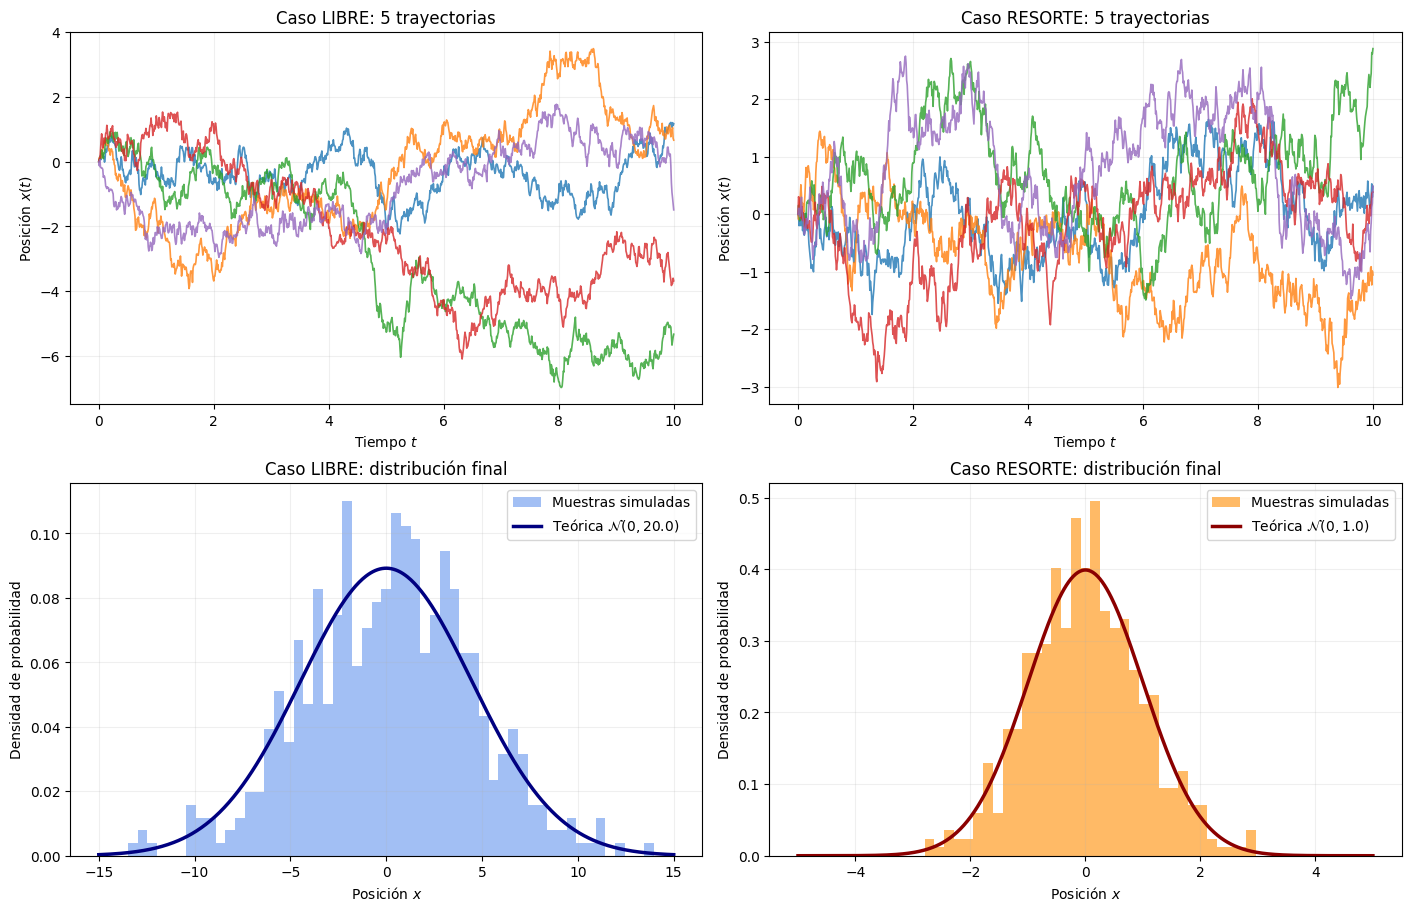

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================
# 1. Parámetros
# ============================================
D = 1.0              # Coeficiente de difusión
k = 1.0              # Constante del resorte
gamma = 1.0          # Coeficiente de fricción
dt = 0.01            # Paso temporal
n_pasos = 1000       # Número de pasos
n_particulas = 500   # Número de partículas

# ============================================
# 2. Simulación del caso LIBRE
# ============================================
# Inicializar posiciones en x=0
x_libre = np.zeros((n_particulas, n_pasos + 1))

# Bucle de simulación
for j in range(n_pasos):
    Z = np.random.normal(size=n_particulas)
    x_libre[:, j+1] = x_libre[:, j] + np.sqrt(2 * D * dt) * Z

# ============================================
# 3. Simulación del caso con RESORTE
# ============================================
x_resorte = np.zeros((n_particulas, n_pasos + 1))

for j in range(n_pasos):
    Z = np.random.normal(size=n_particulas)
    x_resorte[:, j+1] = (x_resorte[:, j]
                         - (k/gamma) * x_resorte[:, j] * dt
                         + np.sqrt(2 * D * dt) * Z)

# ============================================
# 4. Visualización
# ============================================

# Vector de tiempos
t = np.arange(n_pasos + 1) * dt

# --------------------------------------------
# Gráfica 1: Trayectorias del caso LIBRE
# --------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)

# 5 trayectorias individuales (caso libre)
for i in range(5):
    axes[0, 0].plot(t, x_libre[i], alpha=0.8, linewidth=1.2)
axes[0, 0].set_title("Caso LIBRE: 5 trayectorias")
axes[0, 0].set_xlabel("Tiempo $t$")
axes[0, 0].set_ylabel("Posición $x(t)$")
axes[0, 0].grid(alpha=0.2)

# 5 trayectorias individuales (caso con resorte)
for i in range(5):
    axes[0, 1].plot(t, x_resorte[i], alpha=0.8, linewidth=1.2)
axes[0, 1].set_title("Caso RESORTE: 5 trayectorias")
axes[0, 1].set_xlabel("Tiempo $t$")
axes[0, 1].set_ylabel("Posición $x(t)$")
axes[0, 1].grid(alpha=0.2)

# --------------------------------------------
# Gráfica 2: Distribución final (caso LIBRE)
# --------------------------------------------
# Posiciones finales de todas las partículas
x_libre_final = x_libre[:, -1]
x_resorte_final = x_resorte[:, -1]

# Rango para los histogramas (centrado en 0)
bins_libre = np.linspace(-15, 15, 60)
bins_resorte = np.linspace(-5, 5, 60)

# Histograma del caso libre
axes[1, 0].hist(x_libre_final, bins=bins_libre, density=True,
                color="cornflowerblue", alpha=0.6,
                label="Muestras simuladas")

# Gaussiana teórica: N(0, 2Dt)
sigma_libre = np.sqrt(2 * D * t[-1])
x_teo = np.linspace(-15, 15, 500)
gauss_libre = (1 / (sigma_libre * np.sqrt(2 * np.pi))) * \
              np.exp(-x_teo**2 / (2 * sigma_libre**2))
axes[1, 0].plot(x_teo, gauss_libre, color="navy", linewidth=2.5,
                label=f"Teórica $\\mathcal{{N}}(0, {sigma_libre**2:.1f})$")
axes[1, 0].set_title("Caso LIBRE: distribución final")
axes[1, 0].set_xlabel("Posición $x$")
axes[1, 0].set_ylabel("Densidad de probabilidad")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.2)

# --------------------------------------------
# Gráfica 3: Distribución final (caso RESORTE)
# --------------------------------------------
axes[1, 1].hist(x_resorte_final, bins=bins_resorte, density=True,
                color="darkorange", alpha=0.6,
                label="Muestras simuladas")

# Gaussiana teórica: N(0, Dγ/k)
sigma_resorte = np.sqrt(D * gamma / k)
x_teo_r = np.linspace(-5, 5, 500)
gauss_resorte = (1 / (sigma_resorte * np.sqrt(2 * np.pi))) * \
                np.exp(-x_teo_r**2 / (2 * sigma_resorte**2))
axes[1, 1].plot(x_teo_r, gauss_resorte, color="darkred", linewidth=2.5,
                label=f"Teórica $\\mathcal{{N}}(0, {sigma_resorte**2:.1f})$")
axes[1, 1].set_title("Caso RESORTE: distribución final")
axes[1, 1].set_xlabel("Posición $x$")
axes[1, 1].set_ylabel("Densidad de probabilidad")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.2)

plt.show()

In [3]:
# ============================================
# 5. Verificación estadística
# ============================================
print("=" * 50)
print("CASO LIBRE")
print("=" * 50)
print(f"Media final:       {np.mean(x_libre_final):.4f}  (teórica: 0)")
print(f"Varianza final:    {np.var(x_libre_final):.4f}  (teórica: {2*D*t[-1]:.4f})")
print()
print("=" * 50)
print("CASO CON RESORTE")
print("=" * 50)
print(f"Media final:       {np.mean(x_resorte_final):.4f}  (teórica: 0)")
print(f"Varianza final:    {np.var(x_resorte_final):.4f}  (teórica: {D*gamma/k:.4f})")

CASO LIBRE
Media final:       0.1536  (teórica: 0)
Varianza final:    19.4145  (teórica: 20.0000)

CASO CON RESORTE
Media final:       0.0027  (teórica: 0)
Varianza final:    0.9579  (teórica: 1.0000)


# Con modelos tipo Score

# Dinámica de Langevin con un campo score

Para una densidad de probabilidad $p_\theta(\mathbf{x})$,
definimos el campo score como

$$
\mathbf{s}_\theta(\mathbf{x})
=
\nabla_{\mathbf{x}}\log p_\theta(\mathbf{x}).
$$

Este campo apunta hacia la dirección de máximo crecimiento
local del logaritmo de la densidad.

## Relación entre el score y la fuerza

Para una distribución de Boltzmann,

$$
p_\theta(\mathbf{x})
=
\frac{1}{Z_\theta}
\exp\left[-\frac{U_\theta(\mathbf{x})}{k_BT}\right],
$$

el score es

$$
\mathbf{s}_\theta(\mathbf{x})
=
-\frac{1}{k_BT}\nabla_{\mathbf{x}}U_\theta(\mathbf{x}).
$$

Como la fuerza es $\mathbf{F}_\theta=-\nabla U_\theta$,

$$
\mathbf{F}_\theta(\mathbf{x})
=
k_BT\,\mathbf{s}_\theta(\mathbf{x}).
$$

## Ecuación estocástica

La dinámica sobreamortiguada es

$$
d\mathbf{X}_t
=
\frac{\mathbf{F}_\theta(\mathbf{X}_t)}{\gamma}\,dt
+
\sqrt{2D}\,d\mathbf{W}_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Sustituyendo la fuerza por su expresión en términos del score:

$$
d\mathbf{X}_t
=
D\,\mathbf{s}_\theta(\mathbf{X}_t)\,dt
+
\sqrt{2D}\,d\mathbf{W}_t.
$$

El campo produce un desplazamiento dirigido y el ruido
mantiene las fluctuaciones. Durante esta evolución,
$\theta$ permanece fijo.

## Incrementos de Wiener

En $d$ dimensiones,

$$
\Delta\mathbf{W}_n
=
\sqrt{\Delta t}\,\boldsymbol{\epsilon}_n,
\qquad
\boldsymbol{\epsilon}_n\sim\mathcal{N}(\mathbf{0},I_d),
$$

con nuevos vectores independientes en cada paso.

## Actualización numérica

La aproximación de Euler–Maruyama es

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
D\,\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2D\Delta t}\,\boldsymbol{\epsilon}_n.
$$

En unidades donde $D=1$:

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2\Delta t}\,\boldsymbol{\epsilon}_n.
$$

Con el score exacto y condiciones adecuadas de convergencia,
la dinámica continua reproduce $p_\theta$ a tiempos largos.
La actualización numérica introduce un error de discretización.

## Ejemplo: distribución gaussiana

Para una gaussiana con media $\boldsymbol{\mu}$ y
covarianza $vI_d$,

$$
\mathbf{s}(\mathbf{x})
=
-\frac{\mathbf{x}-\boldsymbol{\mu}}{v}.
$$



In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Gaussiana objetivo
mu = 0.0
varianza = 1.0

def densidad(x):
    return np.exp(-(x - mu)**2 / (2 * varianza)) / np.sqrt(
        2 * np.pi * varianza
    )

def score(x):
    return -(x - mu) / varianza



In [5]:
rng = np.random.default_rng(42)

n_trayectorias = 200
n_pasos = 1_000
dt = 0.01

# Todas las trayectorias comienzan en la misma posición
x = np.zeros((n_trayectorias, n_pasos))
np.shape(x)
t = np.arange(n_pasos+1 ) * dt

In [6]:
x = np.zeros((n_trayectorias, n_pasos + 1))

# Todas las trayectorias comienzan en cero
x[:, 0] = 0.0

for k in range(n_trayectorias):
    for j in range(n_pasos):
        ruido = rng.normal()

        x[k, j + 1] = (
            x[k, j]
            + dt * score(x[k, j])
            + np.sqrt(2 * dt) * ruido
        )

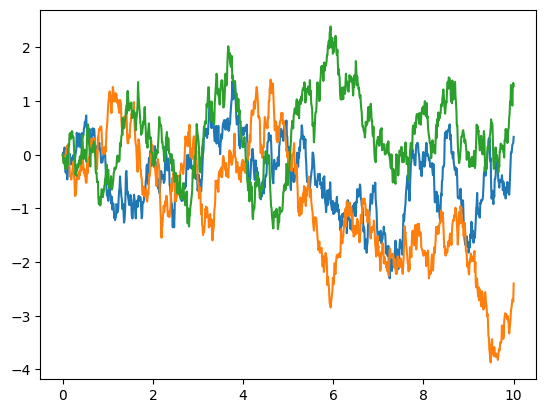

In [7]:
plt.plot(t, x[0])
plt.plot(t, x[1])
plt.plot(t, x[2])

In [8]:
x=np.concat(x)

Media de las muestras:    -0.0092
Varianza de las muestras: 0.9434
Varianza teórica discreta: 1.0050


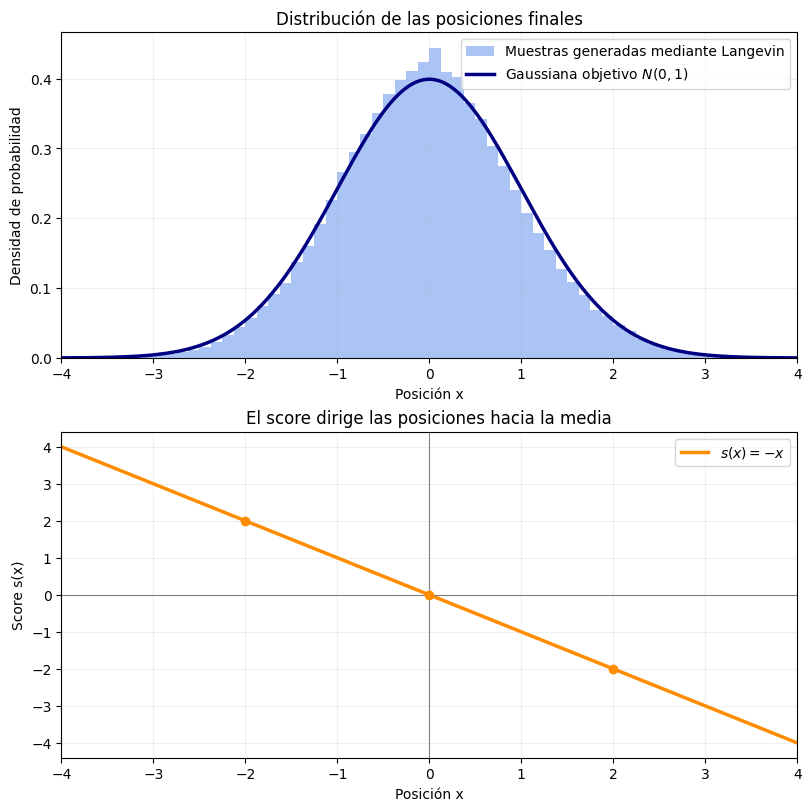

In [9]:
# Resultados
print(f"Media de las muestras:    {np.mean(x):.4f}")
print(f"Varianza de las muestras: {np.var(x):.4f}")

# Varianza estacionaria de la actualización discreta
varianza_discreta = varianza / (1 - dt / (2 * varianza))
print(f"Varianza teórica discreta: {varianza_discreta:.4f}")


# Gráficas
eje = np.linspace(-4, 4, 600)

fig, axes = plt.subplots(
    2, 1, figsize=(8, 8), constrained_layout=True
)

# Densidad objetivo e histograma de posiciones finales
axes[0].hist(
    x,
    bins=np.linspace(-4, 4, 65),
    density=True,
    color="cornflowerblue",
    alpha=0.55,
    label="Muestras generadas mediante Langevin"
)

axes[0].plot(
    eje,
    densidad(eje),
    color="navy",
    linewidth=2.5,
    label=r"Gaussiana objetivo ${N}(0,1)$"
)

axes[0].set(
    title="Distribución de las posiciones finales",
    xlabel="Posición x",
    ylabel="Densidad de probabilidad",
    xlim=(-4, 4)
)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Campo score
axes[1].plot(
    eje,
    score(eje),
    color="darkorange",
    linewidth=2.5,
    label=r"$s(x) = -x$"
)

axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].axvline(mu, color="gray", linewidth=0.8)

axes[1].scatter(
    [-2, 0, 2],
    score(np.array([-2, 0, 2])),
    color="darkorange",
    zorder=3
)

axes[1].set(
    title="El score dirige las posiciones hacia la media",
    xlabel="Posición x",
    ylabel="Score s(x)",
    xlim=(-4, 4)
)
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.show()

Simule la dinámica de Langevin de partículas inicialmente distribuidas al azar en el plano, utilizando el campo score de una gaussiana de media \((0,0)\) y covarianza identidad. Visualice el campo y cinco trayectorias. Compare la distribución final de las partículas con la gaussiana objetivo y calcule su media y covarianza.

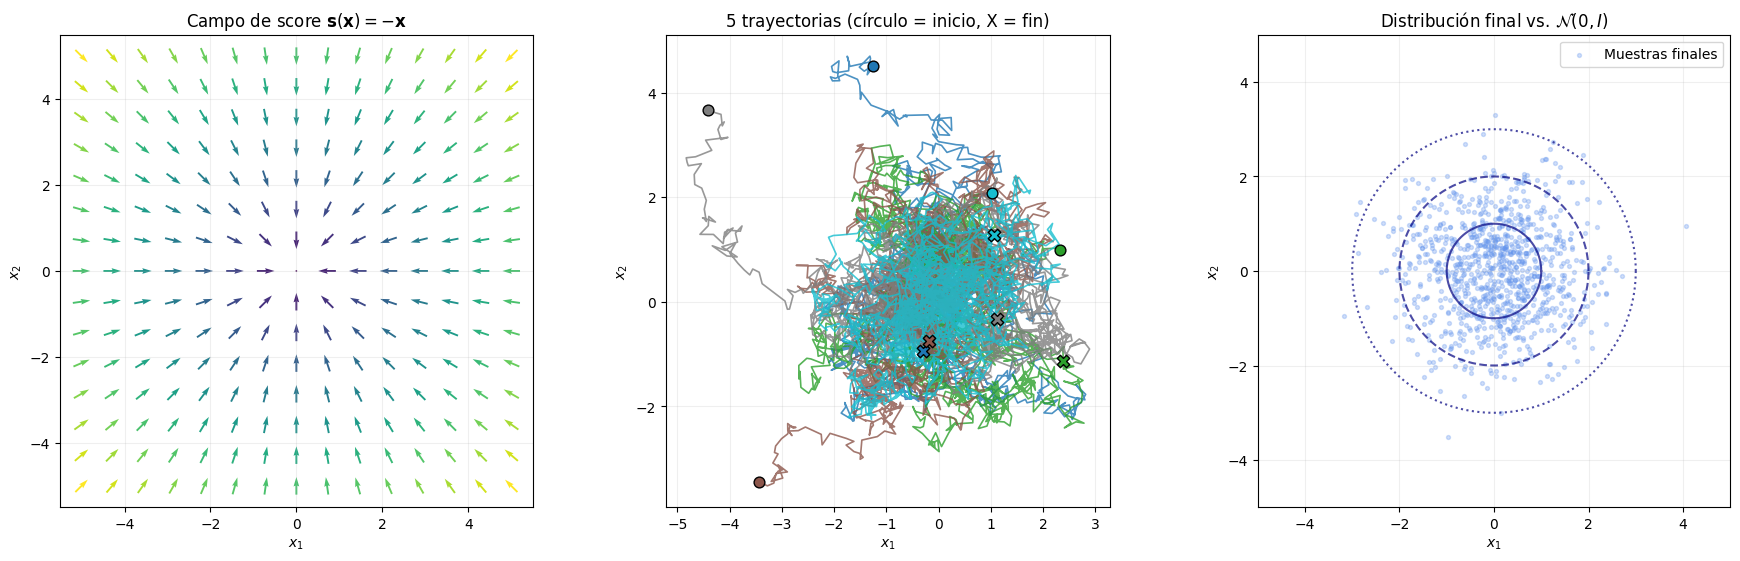

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================
# 1. Parámetros
# ============================================
n_particulas = 1000      # Número de partículas
n_pasos = 2000           # Número de pasos
dt = 0.01                # Paso temporal

# ============================================
# 2. Score de la Gaussiana N(0, I)
# ============================================
def score(X):
    """Score de N(0, I): s(x) = -x"""
    return -X

# ============================================
# 3. Inicialización: partículas al azar en el plano
# ============================================
np.random.seed(42)
# Distribución inicial: uniforme en [-5, 5] x [-5, 5]
X = np.random.uniform(-5, 5, size=(n_particulas, 2))

# Guardar trayectorias (solo 5 partículas para visualizar)
n_tray = 5
trayectorias = np.zeros((n_tray, n_pasos + 1, 2))
trayectorias[:, 0, :] = X[:n_tray]

# ============================================
# 4. Simulación (Euler-Maruyama)
# ============================================
for j in range(n_pasos):
    # Ruido 2D: vector de normales independientes
    Z = np.random.normal(size=(n_particulas, 2))

    # Actualización de Euler-Maruyama
    X = X + score(X) * dt + np.sqrt(2 * dt) * Z

    # Guardar trayectorias de las primeras 5 partículas
    trayectorias[:, j+1, :] = X[:n_tray]

# ============================================
# 5. Visualización
# ============================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)

# --------------------------------------------
# Gráfica 1: Campo de score (quiver)
# --------------------------------------------
# Grilla para el campo vectorial
xx, yy = np.meshgrid(np.linspace(-5, 5, 15), np.linspace(-5, 5, 15))
grid = np.stack([xx, yy], axis=-1)  # shape (15, 15, 2)
S = score(grid)                     # s(x) = -x

# Normalizar para visualización (solo dirección)
magnitud = np.linalg.norm(S, axis=-1, keepdims=True)
S_norm = S / (magnitud + 1e-8)

axes[0].quiver(xx, yy, S_norm[..., 0], S_norm[..., 1],
               magnitud[..., 0], cmap="viridis", pivot="middle")
axes[0].set_title("Campo de score $\\mathbf{s}(\\mathbf{x}) = -\\mathbf{x}$")
axes[0].set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
axes[0].set_aspect("equal")
axes[0].grid(alpha=0.2)

# --------------------------------------------
# Gráfica 2: 5 trayectorias
# --------------------------------------------
colores = plt.cm.tab10(np.linspace(0, 1, n_tray))
for i in range(n_tray):
    axes[1].plot(trayectorias[i, :, 0], trayectorias[i, :, 1],
                 color=colores[i], alpha=0.8, linewidth=1.2)
    # Marcar el punto inicial
    axes[1].scatter(trayectorias[i, 0, 0], trayectorias[i, 0, 1],
                    color=colores[i], marker="o", s=60, edgecolors="black", zorder=5)
    # Marcar el punto final
    axes[1].scatter(trayectorias[i, -1, 0], trayectorias[i, -1, 1],
                    color=colores[i], marker="X", s=80, edgecolors="black", zorder=5)

axes[1].set_title("5 trayectorias (círculo = inicio, X = fin)")
axes[1].set_xlabel("$x_1$")
axes[1].set_ylabel("$x_2$")
axes[1].set_aspect("equal")
axes[1].grid(alpha=0.2)

# --------------------------------------------
# Gráfica 3: Distribución final vs. Gaussiana objetivo
# --------------------------------------------
# Scatter de las posiciones finales
axes[2].scatter(X[:, 0], X[:, 1], alpha=0.3, s=8, color="cornflowerblue",
                label="Muestras finales")

# Círculos de confianza de la gaussiana N(0, I) (1σ, 2σ, 3σ)
theta = np.linspace(0, 2*np.pi, 200)
for r, ls in [(1, "-"), (2, "--"), (3, ":")]:
    axes[2].plot(r*np.cos(theta), r*np.sin(theta),
                 color="navy", linestyle=ls, linewidth=1.5, alpha=0.7)

axes[2].set_title("Distribución final vs. $\\mathcal{N}(0, I)$")
axes[2].set_xlabel("$x_1$")
axes[2].set_ylabel("$x_2$")
axes[2].set_xlim(-5, 5)
axes[2].set_ylim(-5, 5)
axes[2].set_aspect("equal")
axes[2].legend(loc="upper right")
axes[2].grid(alpha=0.2)

plt.show()

In [11]:
# ============================================
# 6. Verificación estadística
# ============================================
media_sim = np.mean(X, axis=0)
cov_sim = np.cov(X, rowvar=False)

print("=" * 55)
print("VERIFICACIÓN ESTADÍSTICA (caso 2D)")
print("=" * 55)
print(f"\nMedia simulada:       {media_sim}")
print(f"Media teórica:        [0. 0.]")
print(f"\nCovarianza simulada:\n{cov_sim}")
print(f"\nCovarianza teórica:\n{np.eye(2)}")
print(f"\nError en la media:    {np.abs(media_sim).round(4)}")
print(f"Error en la varianza: {np.abs(np.diag(cov_sim) - 1).round(4)}")

VERIFICACIÓN ESTADÍSTICA (caso 2D)

Media simulada:       [0.04674918 0.02653185]
Media teórica:        [0. 0.]

Covarianza simulada:
[[ 0.97397528 -0.01040281]
 [-0.01040281  1.01591814]]

Covarianza teórica:
[[1. 0.]
 [0. 1.]]

Error en la media:    [0.0467 0.0265]
Error en la varianza: [0.026  0.0159]
